# BCSE331P – Exploratory Data Analysis
## Assessment 3: Data Cleaning and Univariate Analysis
**Dataset:** `recid.csv` (1445 rows; columns: rownames, black, alcohol, drugs, super, married, felon, workprg, property, person, priors, educ, rules, age, tserved, follow, durat, cens, ldurat).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/recid.csv"

**Q1. Import the dataset**

In [2]:
df = pd.read_csv(URL)

**Note:** the raw file is already clean (no NaNs, duplicates or text columns). To perform the cleaning tasks, two text columns (`race`, `offense_type`) are derived, ~5% NaNs are injected, `rules` is made 75% missing, and 10 duplicate rows are added.

In [3]:
df["race"] = df["black"].map({1: "Black", 0: "Other"})
df["offense_type"] = np.select([df["property"] == 1, df["person"] == 1], ["Property", "Person"], "Other")

rng = np.random.default_rng(42)
for col, p in {"educ": .05, "age": .05, "priors": .08, "tserved": .04, "offense_type": .06, "race": .03, "rules": .75}.items():
    df.loc[rng.random(len(df)) < p, col] = np.nan
df = pd.concat([df, df.sample(10, random_state=1)], ignore_index=True)
df.shape

(1455, 21)

**Q2. First and last six records**

In [4]:
display(df.head(6)); display(df.tail(6))

,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,...,educ,rules,age,tserved,follow,durat,cens,ldurat,race,offense_type
0,1,0,1,0,1,1,0,1,0,0,...,7.0,NaN,441.0,30.0,72,72,1,4.276666,Other,Other
1,2,1,0,0,1,0,1,1,1,0,...,12.0,NaN,307.0,NaN,75,75,1,4.317488,NaN,Property
2,3,0,0,0,0,0,0,1,1,0,...,9.0,5.0,262.0,NaN,81,9,0,2.197225,Other,Property
3,4,0,0,1,1,0,1,1,1,0,...,9.0,NaN,253.0,38.0,76,25,0,3.218876,Other,Property
4,5,0,0,1,1,0,0,0,0,0,...,9.0,NaN,244.0,4.0,81,81,1,4.394449,Other,Other
5,6,1,0,0,1,0,0,1,0,0,...,12.0,NaN,277.0,13.0,79,79,1,4.369448,Black,Other


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,...,educ,rules,age,tserved,follow,durat,cens,ldurat,race,offense_type
1449,38,0,0,0,1,1,0,1,0,0,...,11.0,NaN,298.0,7.0,80,80,1,4.382027,Other,Other
1450,1036,0,0,0,1,0,1,1,1,0,...,12.0,NaN,620.0,49.0,78,20,0,2.995732,Other,Property
1451,1266,1,0,0,0,0,1,0,1,0,...,15.0,NaN,337.0,21.0,76,76,1,4.330733,Black,Property
1452,92,0,0,0,1,0,0,0,0,0,...,11.0,NaN,233.0,14.0,70,70,1,4.248495,Other,Other
1453,1104,1,0,0,0,0,0,0,0,0,...,10.0,NaN,306.0,13.0,74,1,0,0.000000,Black,Other
1454,1396,1,0,0,1,0,0,0,0,0,...,10.0,0.0,256.0,7.0,71,71,1,4.262680,Black,NaN


**Q3. Total number of missing values**

In [5]:
print("Total missing:", df.isna().sum().sum()); df.isna().sum()

Total missing: 1556


,0
rownames,0
black,0
alcohol,0
drugs,0
super,0
married,0
felon,0
workprg,0
property,0
person,0


**Q4. Records containing at least one missing value**

In [6]:
na_rows = df[df.isna().any(axis=1)]
print(len(na_rows), "rows"); na_rows.head(10)

1192 rows


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,...,educ,rules,age,tserved,follow,durat,cens,ldurat,race,offense_type
0,1,0,1,0,1,1,0,1,0,0,...,7.0,NaN,441.0,30.0,72,72,1,4.276666,Other,Other
1,2,1,0,0,1,0,1,1,1,0,...,12.0,NaN,307.0,NaN,75,75,1,4.317488,NaN,Property
2,3,0,0,0,0,0,0,1,1,0,...,9.0,5.0,262.0,NaN,81,9,0,2.197225,Other,Property
3,4,0,0,1,1,0,1,1,1,0,...,9.0,NaN,253.0,38.0,76,25,0,3.218876,Other,Property
4,5,0,0,1,1,0,0,0,0,0,...,9.0,NaN,244.0,4.0,81,81,1,4.394449,Other,Other
5,6,1,0,0,1,0,0,1,0,0,...,12.0,NaN,277.0,13.0,79,79,1,4.369448,Black,Other
7,8,1,0,0,1,0,1,1,1,0,...,10.0,NaN,314.0,34.0,73,73,1,4.290460,Black,Property
9,10,1,0,0,1,1,1,1,0,0,...,11.0,NaN,430.0,32.0,73,60,0,4.094345,Black,Other
10,11,1,1,0,1,1,0,1,0,0,...,6.0,NaN,417.0,4.0,70,70,1,4.248495,Black,Other
11,12,1,0,0,0,0,0,0,0,0,...,12.0,NaN,305.0,9.0,80,73,0,4.290460,Black,Other


**Q5. Remove columns with more than 70% missing values**

In [7]:
pct = df.isna().mean() * 100
drop_cols = pct[pct > 70].index.tolist()
print("Dropped:", drop_cols)
df = df.drop(columns=drop_cols)

Dropped: ['rules']


**Q6. Replace missing numerical values with the mean**

In [8]:
num_cols = df.select_dtypes("number").columns
df_mean = df.copy()
df_mean[num_cols] = df_mean[num_cols].fillna(df_mean[num_cols].mean())
df_mean[num_cols].isna().sum()

,0
rownames,0
black,0
alcohol,0
drugs,0
super,0
married,0
felon,0
workprg,0
property,0
person,0


**Q7. Replace missing numerical values with the median** (this version is used from here on)

In [9]:
df_median = df.copy()
df_median[num_cols] = df_median[num_cols].fillna(df_median[num_cols].median())
df = df_median
df[num_cols].isna().sum()

,0
rownames,0
black,0
alcohol,0
drugs,0
super,0
married,0
felon,0
workprg,0
property,0
person,0


**Q8. Replace missing categorical values with the mode**

In [10]:
for c in ["race", "offense_type"]:
    df[c] = df[c].fillna(df[c].mode()[0])
print("Total missing now:", df.isna().sum().sum())

Total missing now: 0


**Q9. Identify duplicate rows**

In [11]:
print("Duplicate rows:", df.duplicated().sum()); df[df.duplicated(keep=False)].sort_values("rownames").head(6)

Duplicate rows: 10


,rownames,black,alcohol,drugs,super,married,felon,workprg,property,person,priors,educ,age,tserved,follow,durat,cens,ldurat,race,offense_type
37,38,0,0,0,1,1,0,1,0,0,1.0,11.0,298.0,7.0,80,80,1,4.382027,Other,Other
1449,38,0,0,0,1,1,0,1,0,0,1.0,11.0,298.0,7.0,80,80,1,4.382027,Other,Other
91,92,0,0,0,1,0,0,0,0,0,0.0,11.0,233.0,14.0,70,70,1,4.248495,Other,Other
1452,92,0,0,0,1,0,0,0,0,0,0.0,11.0,233.0,14.0,70,70,1,4.248495,Other,Other
1446,530,0,1,0,1,0,0,0,0,0,2.0,9.0,240.0,15.0,72,4,0,1.386294,Other,Other
529,530,0,1,0,1,0,0,0,0,0,2.0,9.0,240.0,15.0,72,4,0,1.386294,Other,Other


**Q10. Remove duplicate rows**

In [12]:
df = df.drop_duplicates().reset_index(drop=True); print("Shape:", df.shape)

Shape: (1445, 20)


**Q11. Columns stored with incorrect data types**  
(0/1 flag columns are stored as integers but are really categorical; `rownames` is only an ID)

In [13]:
print(df.dtypes, "\n")
wrong = [c for c in df.columns if c != "rownames" and df[c].dtype != "object" and df[c].nunique() <= 2]
print("Binary-coded columns that should be categorical:", wrong)

rownames          int64
black             int64
alcohol           int64
drugs             int64
super             int64
married           int64
felon             int64
workprg           int64
property          int64
person            int64
priors          float64
educ            float64
age             float64
tserved         float64
follow            int64
durat             int64
cens              int64
ldurat          float64
race             object
offense_type     object
dtype: object 

Binary-coded columns that should be categorical: ['black', 'alcohol', 'drugs', 'super', 'married', 'felon', 'workprg', 'property', 'person', 'cens']


**Q12. Convert character (and binary-coded) variables into factors**

In [14]:
for c in df.select_dtypes(exclude="number").columns.tolist() + wrong:
    df[c] = df[c].astype("category")
df.dtypes

,0
rownames,int64
black,category
alcohol,category
drugs,category
super,category
married,category
felon,category
workprg,category
property,category
person,category


**Q13. Convert text values to lowercase / uppercase**

In [15]:
upper_demo = df["offense_type"].astype(str).str.upper()
for c in ["race", "offense_type"]:
    df[c] = df[c].astype(str).str.lower().astype("category")
print("Lowercase:", df["offense_type"].unique().tolist())
print("Uppercase:", upper_demo.unique().tolist())

Lowercase: ['other', 'property', 'person']
Uppercase: ['OTHER', 'PROPERTY', 'PERSON']


**Q14. Detect outliers using boxplots**

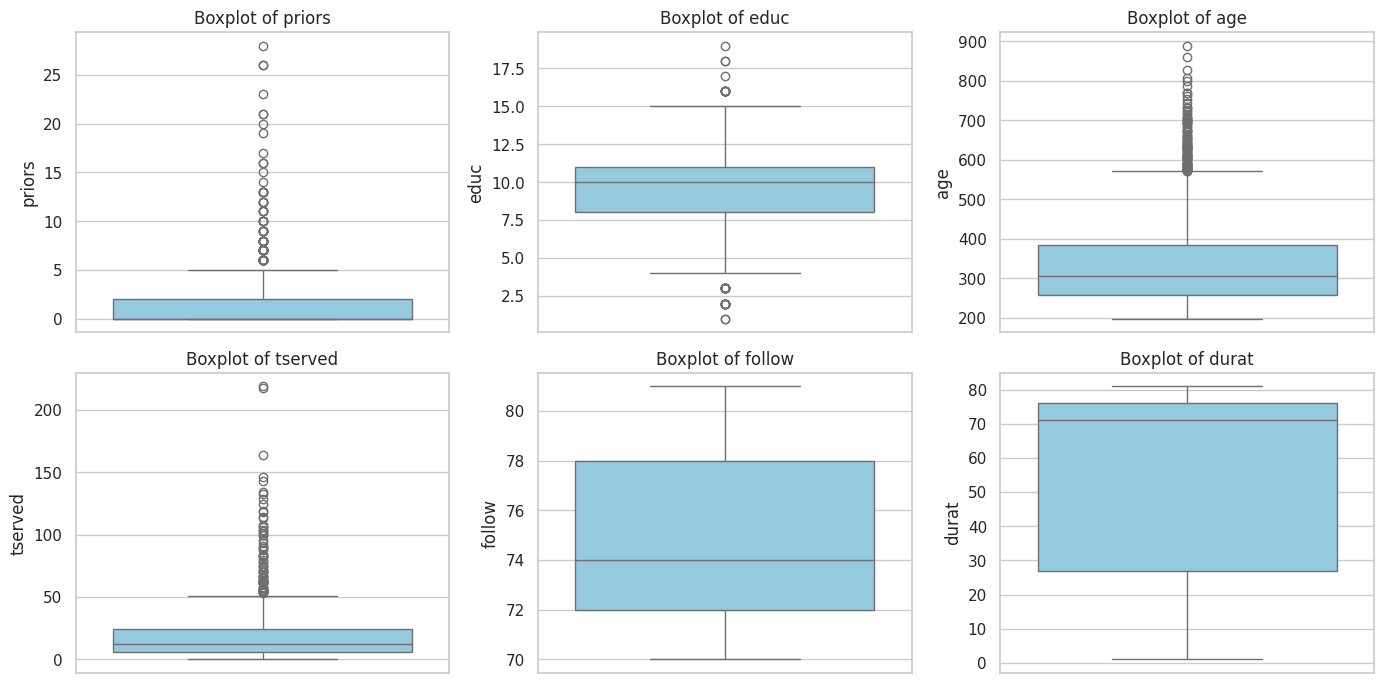

In [16]:
num_vars = ["priors", "educ", "age", "tserved", "follow", "durat"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, v in zip(axes.ravel(), num_vars):
    sns.boxplot(y=df[v], ax=ax, color="skyblue"); ax.set_title(f"Boxplot of {v}")
plt.tight_layout(); plt.show()

**Q15. Outliers using the IQR method**

In [17]:
rows = []
for v in num_vars:
    q1, q3 = df[v].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    rows.append([v, q1, q3, iqr, lo, hi, ((df[v] < lo) | (df[v] > hi)).sum()])
pd.DataFrame(rows, columns=["Variable", "Q1", "Q3", "IQR", "Lower fence", "Upper fence", "No. of outliers"]).round(2)

,Variable,Q1,Q3,IQR,Lower fence,Upper fence,No. of outliers
0,priors,0.0,2.0,2.0,-3.0,5.0,105
1,educ,8.0,11.0,3.0,3.5,15.5,46
2,age,259.0,384.0,125.0,71.5,571.5,97
3,tserved,6.0,24.0,18.0,-21.0,51.0,73
4,follow,72.0,78.0,6.0,63.0,87.0,0
5,durat,27.0,76.0,49.0,-46.5,149.5,0


**Q16. Remove extreme outliers** (beyond 3 × IQR)

In [18]:
mask = pd.Series(True, index=df.index)
for v in num_vars:
    q1, q3 = df[v].quantile([.25, .75]); iqr = q3 - q1
    mask &= df[v].between(q1 - 3*iqr, q3 + 3*iqr)
df_clean = df[mask].reset_index(drop=True)
print("Before:", df.shape, "| After:", df_clean.shape)

Before: (1445, 20) | After: (1368, 20)


**Q17. Histogram and interpretation** (variable: `age`)

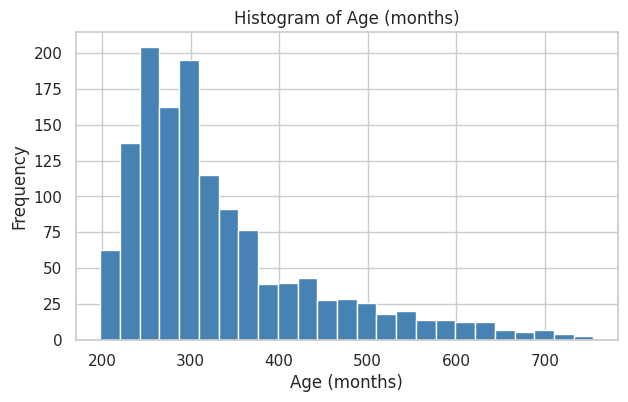

Skewness = 1.45 -> distribution is right-skewed (long tail of older inmates)
Mean = 334.2, Median = 306.0


In [19]:
plt.figure(figsize=(7,4))
plt.hist(df_clean["age"], bins=25, color="steelblue", edgecolor="white")
plt.title("Histogram of Age (months)"); plt.xlabel("Age (months)"); plt.ylabel("Frequency"); plt.show()
sk = df_clean["age"].skew()
print(f"Skewness = {sk:.2f} -> distribution is", "right-skewed (long tail of older inmates)" if sk > 0.5 else "left-skewed" if sk < -0.5 else "roughly symmetric")
print(f"Mean = {df_clean['age'].mean():.1f}, Median = {df_clean['age'].median():.1f}")

**Q18. Add a density curve to the histogram**

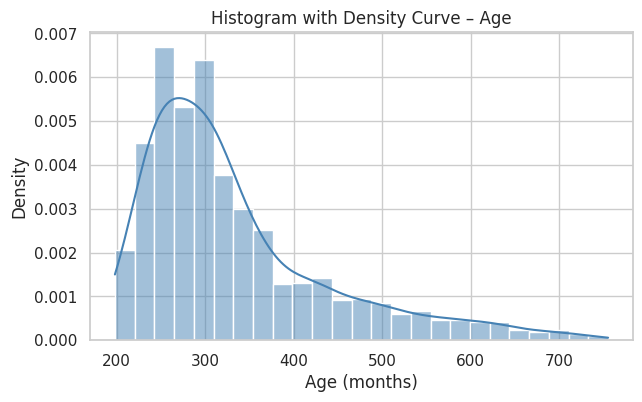

In [20]:
plt.figure(figsize=(7,4))
sns.histplot(df_clean["age"], bins=25, stat="density", kde=True, color="steelblue")
plt.title("Histogram with Density Curve – Age"); plt.xlabel("Age (months)"); plt.show()

**Q19. Violin plot**

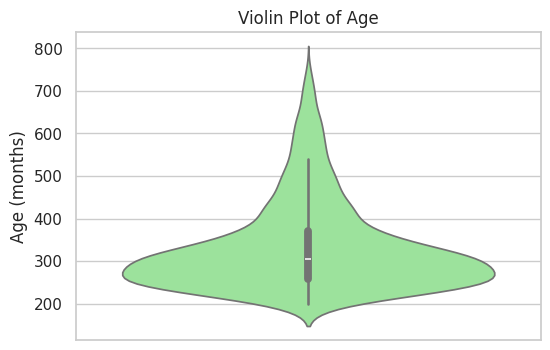

In [21]:
plt.figure(figsize=(6,4)); sns.violinplot(y=df_clean["age"], color="lightgreen")
plt.title("Violin Plot of Age"); plt.ylabel("Age (months)"); plt.show()

**Q20. Dot plot for a small numerical dataset** (15 values of `educ`)

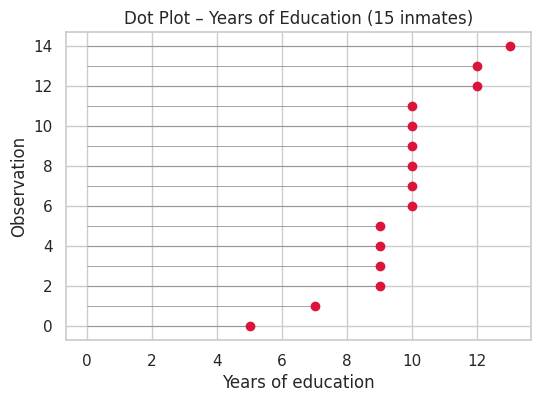

In [22]:
small = df_clean["educ"].sample(15, random_state=1).sort_values().reset_index(drop=True)
plt.figure(figsize=(6,4))
plt.hlines(range(15), 0, small, color="grey", lw=.5); plt.plot(small, range(15), "o", color="crimson")
plt.title("Dot Plot – Years of Education (15 inmates)"); plt.xlabel("Years of education"); plt.ylabel("Observation"); plt.show()

**Q21. Frequency table** (`offense_type`)

In [23]:
freq = df_clean["offense_type"].value_counts()
freq.to_frame("Frequency")

,Frequency
offense_type,
other,985
property,321
person,62


**Q22. Proportion and percentage of each category**

In [24]:
pd.DataFrame({"Frequency": freq, "Proportion": (freq / freq.sum()).round(4), "Percentage": (freq / freq.sum() * 100).round(2)})

,Frequency,Proportion,Percentage
offense_type,,,
other,985,0.7200,72.00
property,321,0.2346,23.46
person,62,0.0453,4.53


**Q23. Bar chart of frequencies**

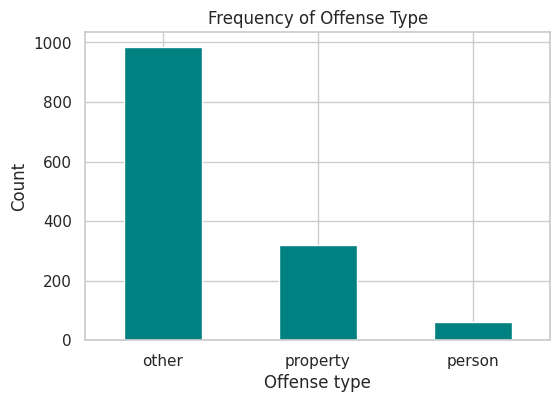

In [25]:
plt.figure(figsize=(6,4)); freq.plot(kind="bar", color="teal", rot=0)
plt.title("Frequency of Offense Type"); plt.xlabel("Offense type"); plt.ylabel("Count"); plt.show()

**Q24. Horizontal bar chart for a variable with several categories** (`educ` – years of education)

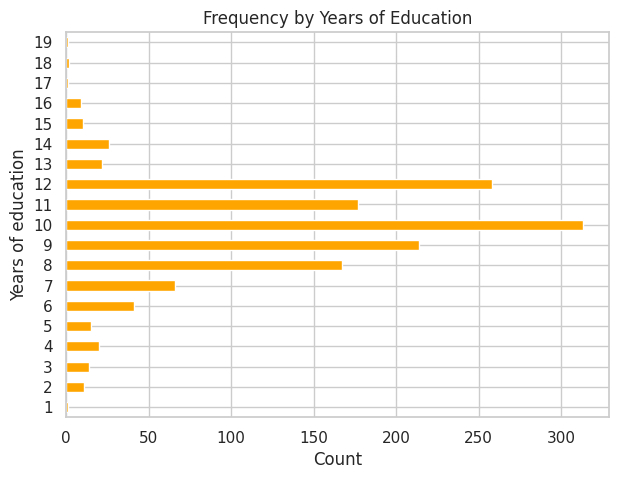

In [26]:
edu = df_clean["educ"].astype(int).value_counts().sort_index()
plt.figure(figsize=(7,5)); edu.plot(kind="barh", color="orange")
plt.title("Frequency by Years of Education"); plt.xlabel("Count"); plt.ylabel("Years of education"); plt.show()

**Q25. Percentage bar chart**

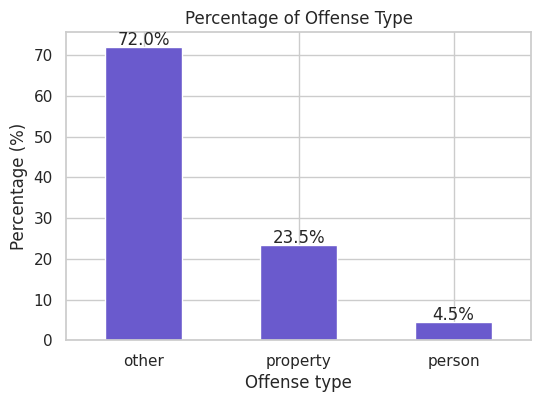

In [27]:
pct_off = (freq / freq.sum() * 100)
ax = pct_off.plot(kind="bar", color="slateblue", rot=0, figsize=(6,4))
for i, v in enumerate(pct_off): ax.text(i, v + .5, f"{v:.1f}%", ha="center")
plt.title("Percentage of Offense Type"); plt.xlabel("Offense type"); plt.ylabel("Percentage (%)"); plt.show()

**Q26. Pie chart**

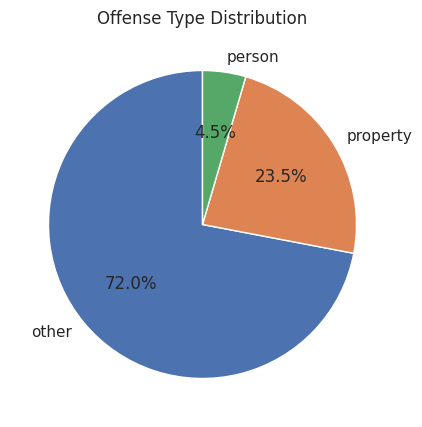

In [28]:
plt.figure(figsize=(5,5)); plt.pie(freq, labels=freq.index, autopct="%1.1f%%", startangle=90)
plt.title("Offense Type Distribution"); plt.show()

**Q27. Lollipop chart**

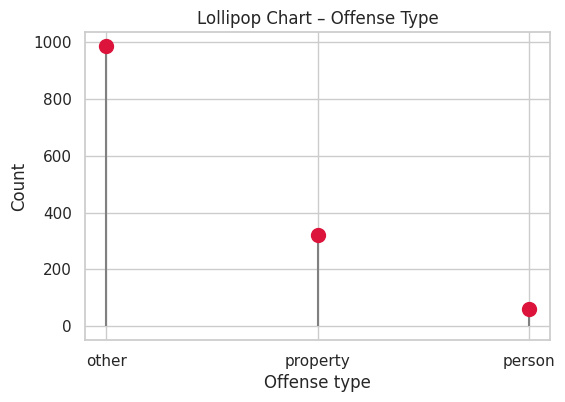

In [29]:
plt.figure(figsize=(6,4))
plt.vlines(freq.index, 0, freq.values, color="grey"); plt.plot(freq.index, freq.values, "o", ms=10, color="crimson")
plt.title("Lollipop Chart – Offense Type"); plt.xlabel("Offense type"); plt.ylabel("Count"); plt.show()

**Q28. Dot chart**

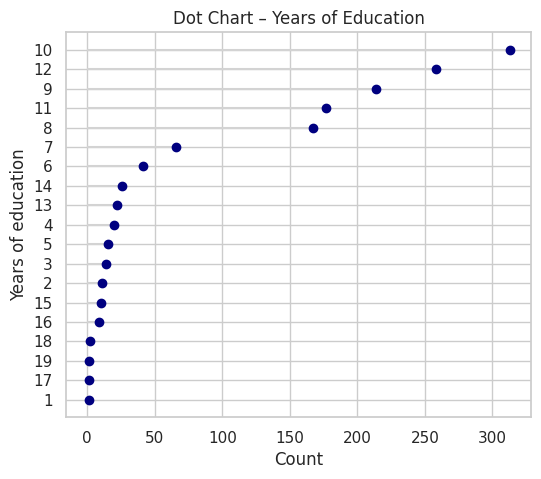

In [30]:
e = edu.sort_values()
plt.figure(figsize=(6,5)); plt.hlines(range(len(e)), 0, e.values, color="lightgrey"); plt.plot(e.values, range(len(e)), "o", color="navy")
plt.yticks(range(len(e)), e.index); plt.title("Dot Chart – Years of Education"); plt.xlabel("Count"); plt.ylabel("Years of education"); plt.show()

**Q29. Density plot (seaborn)**

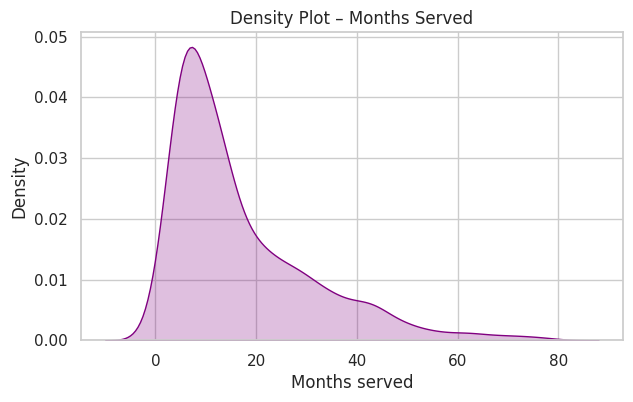

In [31]:
plt.figure(figsize=(7,4)); sns.kdeplot(df_clean["tserved"], fill=True, color="purple")
plt.title("Density Plot – Months Served"); plt.xlabel("Months served"); plt.show()

**Q30. Facets – distribution of `age` across offense types**

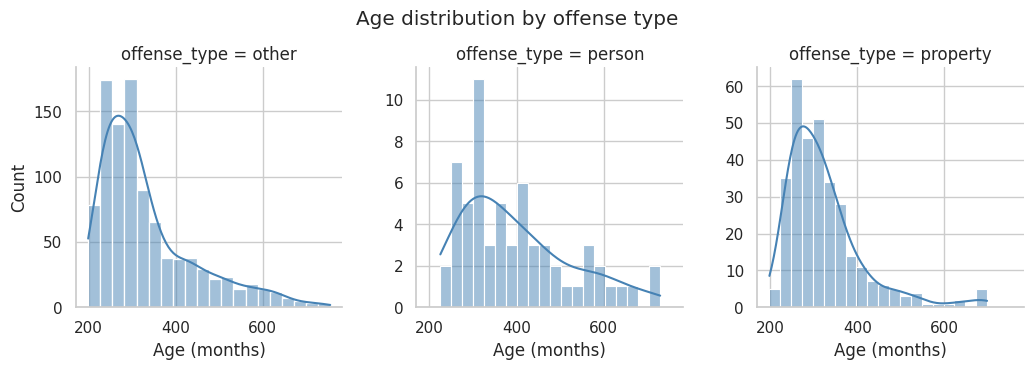

,count,mean,median,std,skew,shape
offense_type,,,,,,
other,985,333.55,303.0,110.32,1.38,right-skewed
person,62,398.58,361.0,126.50,0.90,right-skewed
property,321,323.59,306.0,88.98,1.92,right-skewed


In [32]:
g = sns.FacetGrid(df_clean, col="offense_type", height=3.5, sharey=False)
g.map(sns.histplot, "age", bins=20, kde=True, color="steelblue")
g.set_axis_labels("Age (months)", "Count"); g.fig.suptitle("Age distribution by offense type", y=1.05); plt.show()

# interpretation of each distribution
summary = df_clean.groupby("offense_type")["age"].agg(["count", "mean", "median", "std", "skew"]).round(2)
summary["shape"] = np.where(summary["skew"] > 0.5, "right-skewed", np.where(summary["skew"] < -0.5, "left-skewed", "symmetric"))
summary